Epoch [1/2], Loss: 0.0000
Epoch [2/2], Loss: 0.0000


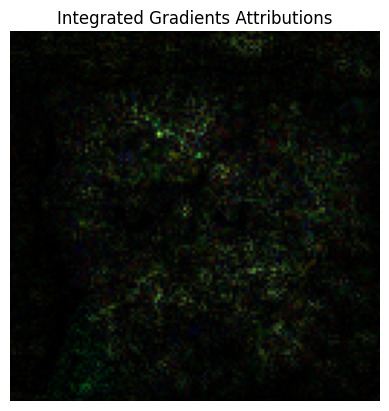

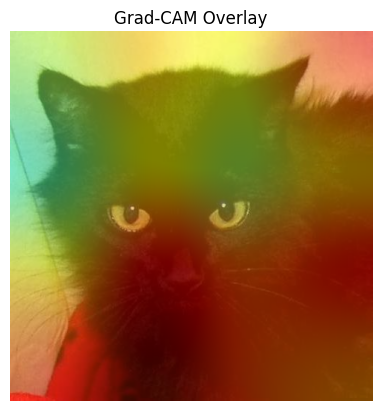

In [ ]:



!pip install torch torchvision captum datasets

import torch
import torchvision.transforms as transforms
from torchvision import models
import torch.nn as nn
import torch.optim as optim
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients, LayerGradCam
from datasets import load_dataset
from torch.utils.data import DataLoader


dataset = load_dataset("pantelism/cats-vs-dogs")



def load_image(image):
    preprocess = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
    ])
    image_tensor = preprocess(image).unsqueeze(0)
    return image_tensor




class CatsVsDogsDataset(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset['train'])

    def __getitem__(self, idx):
        img = self.dataset['train'][idx]['image'].convert("RGB")
        label = 1 if 'dog' in self.dataset['train'][idx]['image'].filename else 0
        img_tensor = load_image(img)
        return img_tensor.squeeze(0), label

small_dataset = dataset['train'].select(range(100))
cats_vs_dogs_dataset = CatsVsDogsDataset({'train': small_dataset})
train_loader = DataLoader(cats_vs_dogs_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)


model = models.resnet50(pretrained=True)


num_classes = 2
model.fc = nn.Linear(model.fc.in_features, num_classes)


for param in model.parameters():
    param.requires_grad = False


for param in model.fc.parameters():
    param.requires_grad = True


model.train()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)



num_epochs = 2
for epoch in range(num_epochs):
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')


model.eval()

example_image = dataset['train'][0]['image'].convert("RGB")
input_image = load_image(example_image)



ig = IntegratedGradients(model)
baseline = torch.zeros(input_image.size()).to(input_image.device)

with torch.no_grad():
    output = model(input_image)
    target_class = output.argmax(dim=1).item()

attributions, _ = ig.attribute(input_image, target=target_class, baselines=baseline, return_convergence_delta=True)

def visualize_attributions(attributions):
    attributions = attributions.squeeze().permute(1, 2, 0).detach().numpy()
    attributions = np.abs(attributions)
    plt.imshow(attributions, cmap='hot')
    plt.axis('off')
    plt.title('Integrated Gradients Attributions')
    plt.show()

visualize_attributions(attributions)




target_layer = model.layer4
grad_cam = LayerGradCam(model, target_layer)


grayscale_cam = grad_cam.attribute(input_image, target=target_class)
grayscale_cam = grayscale_cam.squeeze().detach().numpy()


def overlay_cam_on_image(original_image, grayscale_cam):
    original_size = original_image.size
    grayscale_cam = np.maximum(grayscale_cam, 0)
    grayscale_cam = grayscale_cam / grayscale_cam.max()
    heatmap = plt.cm.jet(grayscale_cam)[..., :3]
    heatmap = Image.fromarray((heatmap * 255).astype(np.uint8))


    heatmap = heatmap.resize(original_size, Image.LANCZOS)


    overlay = Image.blend(original_image, heatmap, alpha=0.5)

    plt.imshow(overlay)
    plt.axis('off')
    plt.title('Grad-CAM Overlay')
    plt.show()

overlay_cam_on_image(example_image, grayscale_cam)









# Cats vs. Dogs Classification with Transfer Learning

In this notebook, we will perform image classification on the Cats vs. Dogs dataset using a pre-trained ResNet model. We will also implement two explainability techniques: Integrated Gradients and Grad-CAM, to understand the model's decision-making process.

## 1. Setup and Import Libraries

We will begin by installing and importing the necessary libraries.

## 2. Load the Dataset

We will use the Cats vs. Dogs dataset available from Hugging Face's `datasets` library.
This dataset contains images of cats and dogs, and our goal is to classify them correctly.

# Load the Cats vs. Dogs dataset
dataset = load_dataset("pantelism/cats-vs-dogs")

## 3. Image Preprocessing

We will define a function to preprocess the images. This includes resizing the images, converting them to tensors, and normalizing them.

## 4. Create Data Loader

We'll create a custom dataset class to load images and labels, and then set up a DataLoader to manage our training data.
## 5. Transfer Learning with ResNet

We will load a pre-trained ResNet model, modify the final layer for our specific task, and prepare the model for training.
## 6. Training the Model

We will run a simple training loop to train the model on our dataset.
## 7. Model Evaluation

After training, we will evaluate the model using Integrated Gradients and Grad-CAM to visualize the model's decision-making process.
## 8. Integrated Gradients

### Explanation
Integrated Gradients is a technique that attributes the model's output to its input features by integrating gradients along the path from a baseline to the input. It helps in understanding which pixels contributed most to the prediction.

### Compute Attributions
## 9. Grad-CAM

### Explanation
Grad-CAM (Gradient-weighted Class Activation Mapping) is another technique that produces a heatmap of important regions in the input image for the predicted class. It uses the gradients of the class score with respect to the feature maps of the last convolutional layer to highlight the regions that influenced the decision.

### Compute Grad-CAM
## 10. Overlay Grad-CAM on the Original Image

We will overlay the Grad-CAM heatmap on the original image to visualize the important regions.
